# Mining nature from the web
### Project 14

How does a search engine see **"climate change"**? We collect the top-100 search
snippets from Google, then measure their redundancy, sentiment, message, and source quality as
we move down the ranking.

In [1]:
import re

import matplotlib.pyplot as plt
import pandas as pd
import simplemma
from wordcloud import STOPWORDS, WordCloud

from climate_mining.paths import RAW

BLUE, INK = "#2a78d6", "#52514e"
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "axes.titlelocation": "left",
        "axes.titleweight": "bold",
        "grid.color": "#e1e0d9",
    }
)
pd.set_option("display.max_colwidth", 120)

## 1. Search results

Pick a run from `data/raw/` (default: newest SerpAPI run).

In [2]:
runs = sorted(RAW.glob("*.xlsx"), reverse=True)  # newest first
[r.name for r in runs]

['20261014-200834_serpapi_google_us.xlsx',
 '20261014-194822_serpapi_us.xlsx',
 '20261014-194047_ddgs_yahoo_us-en.xlsx']

In [3]:
RUN = next(r for r in runs if "_serpapi_" in r.name)  # or e.g. runs[1]
sheets = pd.read_excel(RUN, sheet_name=None)
df = sheets["snippets"]
meta = sheets["meta"].set_index("key")["value"].dropna().to_dict()
meta

{'query': 'climate change',
 'provider': 'serpapi',
 'engine': 'google',
 'region': 'us',
 'count': 100,
 'timestamp': '2026-10-14T17:08:34+00:00'}

In [4]:
df["domain"] = df.url.str.extract(r"https?://(?:www\.)?([^/]+)")
print(f"{len(df)} results from {df.domain.nunique()} domains")
df[["rank", "domain", "snippet"]].head(10)

100 results from 60 domains


,rank,domain,snippet
0,1,un.org,"Climate change refers to long-term shifts in temperatures and weather patterns. Such shifts can be natural, due to c..."
1,2,science.nasa.gov,There is unequivocal evidence that Earth is warming at an unprecedented rate. Human activity is the principal cause.
2,3,en.wikipedia.org,"Climate change threatens people with increased flooding, extreme heat, increased food and water scarcity, more disea..."
3,4,noaa.gov,"Climate change affects the environment in many different ways, including rising temperatures, sea level rise, drough..."
4,5,epa.gov,"EPA tracks and reports greenhouse gas emissions, leverages sound science, and invests in America to combat climate c..."
5,6,who.int,Climate change is impacting human lives and health in a variety of ways. It threatens the essential ingredients of g...
6,7,royalsociety.org,"Earth's climate balance has been altered towards warming, with the biggest contributor being increases in CO2. Warmi..."
7,8,climate.colorado.gov,"What is climate change? Global climate change refers to a long-term change in temperatures, either warming or coolin..."
8,9,nature.com,Nature Climate Change is dedicated to publishing the most significant research across the physical and social scienc...
9,10,britannica.com,"Climate change, the periodic modification of Earth's climate caused by atmospheric changes and the atmosphere's inte..."


## 2. WordCloud of all snippets

All snippets are cleaned and concatenated into one document. Cleaning removes URLs, SERP breadcrumbs (`·`), truncation marks (`...`) and separator lines. Words are then lemmatised (*rising → rise*, *gases → gas*) so one concept is counted once, and `wordcloud` drops stopwords and keeps frequent two-word collocations (*sea level*, *greenhouse gas*).

The query words *climate* and *change* appear in almost every snippet, so they swamp everything else. The left cloud keeps them for reference; the right one removes them (plus web boilerplate like *news*, *video*, *learn*) to show what the results talk about.

In [5]:
URL = re.compile(r"https?://\S+|www\.\S+")
RULES = re.compile(r"-{3,}|\|")  # "---------- II ----------", "a | b"
BULLET = re.compile(r"\s*[·•]\s*")  # SERP breadcrumbs / inline lists
ELLIPSIS = re.compile(r"\.\.\.|…")
WORD = re.compile(r"[A-Za-z][A-Za-z'-]*")

# Lemmas that would destroy a meaningful term ("global warming" -> "global warm")
KEEP = {"warming", "data", "news", "species"}

# The query itself would dominate every frequency count
QUERY_WORDS = {"climate", "change", "changes", "changing"}

# SERP/web boilerplate that says nothing about how climate change is framed
WEB_WORDS = {
    "comments", "views", "video", "channel", "news", "coverage", "latest",
    "read", "learn", "explore", "explained", "lesson", "report", "reports",
    "published", "update", "share", "shareable", "subscribe", "click",
    "will", "may", "also", "one", "two", "many", "new", "us", "way", "end",
    "include", "now", "make", "take", "say", "stay", "professor",
}  # fmt: skip
STOP = set(STOPWORDS) | WEB_WORDS


def clean_snippet(s: str) -> str:
    s = URL.sub(" ", str(s))
    s = RULES.sub(" ", s)
    s = BULLET.sub(". ", s)
    s = ELLIPSIS.sub(" ", s)
    return re.sub(r"\s+", " ", s).strip(" .")


def lemmatize(text: str) -> str:
    """Map inflections to one form (rising -> rise, gases -> gas)."""

    def lemma(m: re.Match) -> str:
        w = m.group()
        return w if w.lower() in KEEP else simplemma.lemmatize(w, lang="en")

    return WORD.sub(lemma, text)

In [6]:
document = lemmatize(" ".join(df.snippet.map(clean_snippet)))
print(f"{len(document.split())} words, {len(document)} characters\n")
print(document[:600], "...")

2209 words, 13501 characters

climate change refer to long-term shift in temperature and weather pattern. such shift can be natural, due to change in the sun activity or large there be unequivocal evidence that Earth be warming at a unprecedented rate. human activity be the principal cause climate change threaten people with increase flooding, extreme heat, increase food and water scarcity, more disease, and economic loss climate change affect the environment in many different way, include rise temperature, sea level rise, drought, flooding, and more EPA track and report greenhouse gas emission, leverage sound science, and ...


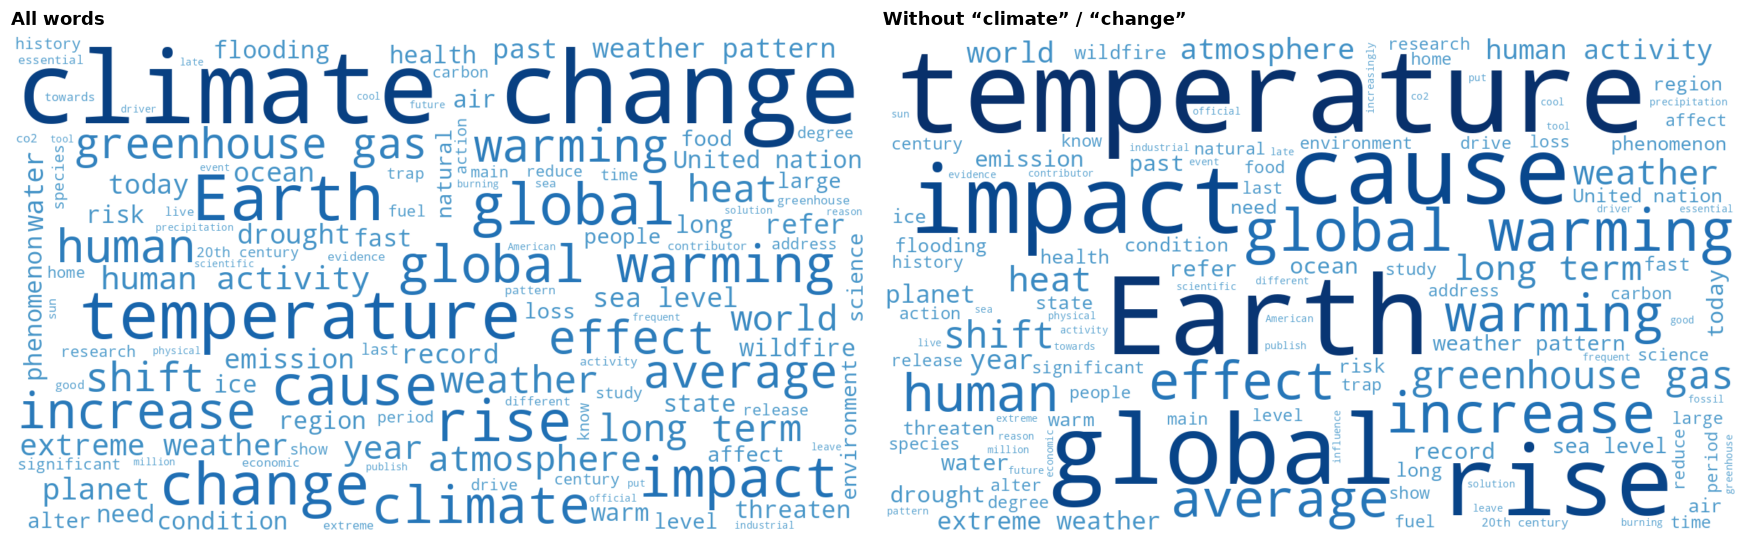

In [7]:
def color_by_size(word, font_size, position, orientation, random_state=None, **kw):
    """Sequential blue: bigger (more frequent) words are darker."""
    r, g, b, _ = plt.cm.Blues(0.5 + 0.5 * font_size / MAX_FONT)
    return f"rgb({r * 255:.0f}, {g * 255:.0f}, {b * 255:.0f})"


MAX_FONT = 160


def make_cloud(text: str, drop_query: bool) -> WordCloud:
    return WordCloud(
        width=1200,
        height=700,
        background_color="white",
        stopwords=STOP | QUERY_WORDS if drop_query else STOP,
        min_word_length=3,
        max_words=120,
        max_font_size=MAX_FONT,
        margin=8,
        prefer_horizontal=0.95,
        color_func=color_by_size,
        random_state=42,
    ).generate(text)


clouds = {
    "All words": make_cloud(document, drop_query=False),
    "Without “climate” / “change”": make_cloud(document, drop_query=True),
}
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))
for ax, (title, wc) in zip(axes, clouds.items(), strict=True):
    ax.imshow(wc, interpolation="bilinear")
    ax.set_title(title)
    ax.axis("off")
fig.tight_layout()

The same counts as a ranked bar chart, which makes sizes easier to compare.

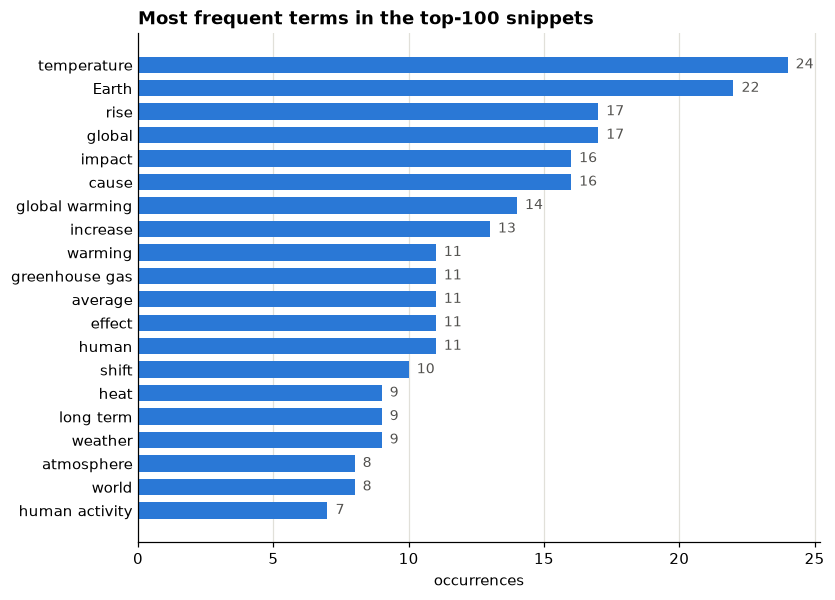

In [8]:
counts = clouds["Without “climate” / “change”"].process_text(document)
top = pd.Series(counts).sort_values().tail(20)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top.values, height=0.7, color=BLUE)
for y, v in enumerate(top.values):
    ax.text(v + 0.3, y, str(v), va="center", fontsize=9, color=INK)
ax.set_title("Most frequent terms in the top-100 snippets")
ax.set_xlabel("occurrences")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)

**Observations (US run, Oct 2026).** The top results frame climate change mainly as *explanatory science*: the dominant terms are physical (*temperature*, *Earth*, *rise*, *greenhouse gas*, *atmosphere*) and causal (*cause*, *human activity*, *long term*, *shift*), which matches the many definition-style snippets from UN, NASA, NOAA and EPA at the top. Impact words (*drought*, *flooding*, *wildfire*, *heat*, *health*, *risk*) form a clear second tier, while action- or solution-oriented vocabulary (*action*, *solution*, *reduce*, *address*) is barely visible. The results explain what climate change is much more often than what to do about it; steps 4 and 5 check this with sentiment scores and the LLM's list of suggested actions.

## 3. Fuzzy similarity of snippets (V1–V3)

In [9]:
import itertools

import numpy as np
from thefuzz import fuzz

snips = df.sort_values("rank").snippet.astype(str).tolist()
n = len(snips)


def score_matrix(scorer):
    M = np.zeros((n, n))
    for i, j in itertools.combinations(range(n), 2):
        M[i, j] = M[j, i] = scorer(snips[i], snips[j])
    return M


def fuzzy_stats(M, step=10):
    rows = []
    for k in range(step, n + 1, step):
        s = M[:k, :k][np.triu_indices(k, 1)]  # the k(k-1)/2 pairs
        rows.append(
            {"k": k, "V1": int((s == 100).sum()), "V2": s.mean(), "V3": s.std()}
        )
    return pd.DataFrame(rows).set_index("k")


M = score_matrix(fuzz.ratio)
fz = fuzzy_stats(M)
fz.round(2)

,V1,V2,V3
k,,,
10,0,45.36,4.00
20,0,44.99,3.53
30,0,43.94,3.57
40,0,43.51,3.73
50,0,42.95,4.12
60,0,43.26,4.14
70,0,43.16,4.08
80,0,42.99,4.15
90,0,42.64,4.09


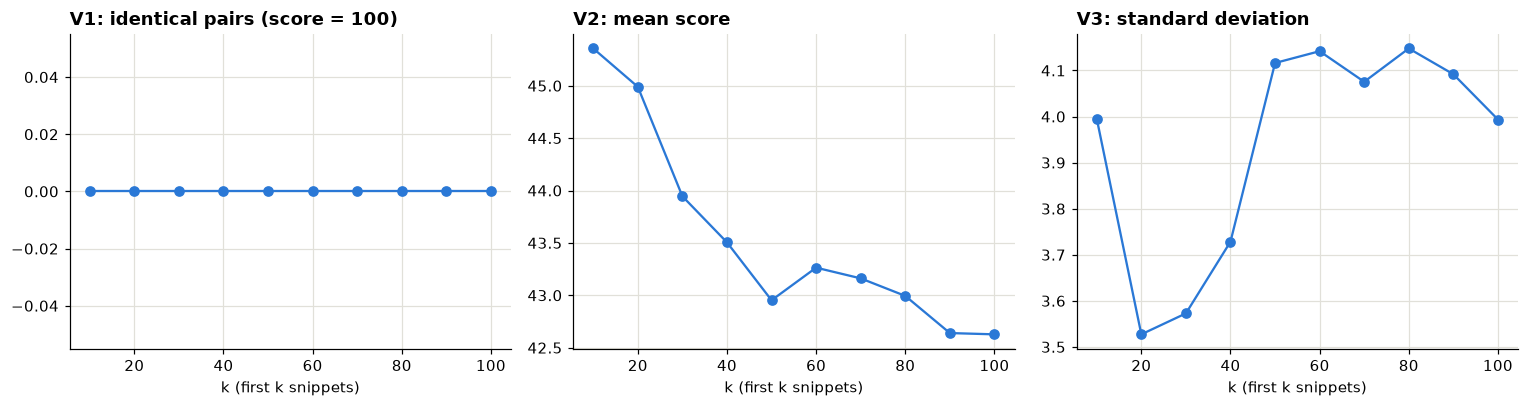

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
titles = {
    "V1": "V1: identical pairs (score = 100)",
    "V2": "V2: mean score",
    "V3": "V3: standard deviation",
}
for ax, (col, title) in zip(axes, titles.items(), strict=True):
    ax.plot(fz.index, fz[col], marker="o", color=BLUE)
    ax.set_title(title)
    ax.set_xlabel("k (first k snippets)")
fig.tight_layout()

## 4. VADER sentiment of snippets (V4–V5)

In [11]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

vader = SentimentIntensityAnalyzer()
d = df.sort_values("rank").reset_index(drop=True)
d["compound"] = d.snippet.astype(str).map(
    lambda s: vader.polarity_scores(s)["compound"]
)


def sentiment_stats(scores, step=10):
    rows = []
    for k in range(step, len(scores) + 1, step):
        s = scores[:k]
        rows.append({"k": k, "V4": s.mean(), "V5": s.std(ddof=0)})
    return pd.DataFrame(rows).set_index("k")


sent = sentiment_stats(d.compound.to_numpy())
sent.round(3)

,V4,V5
k,,
10,0.185,0.307
20,0.110,0.294
30,0.114,0.287
40,0.090,0.294
50,0.083,0.326
60,0.076,0.316
70,0.081,0.328
80,0.078,0.319
90,0.069,0.327


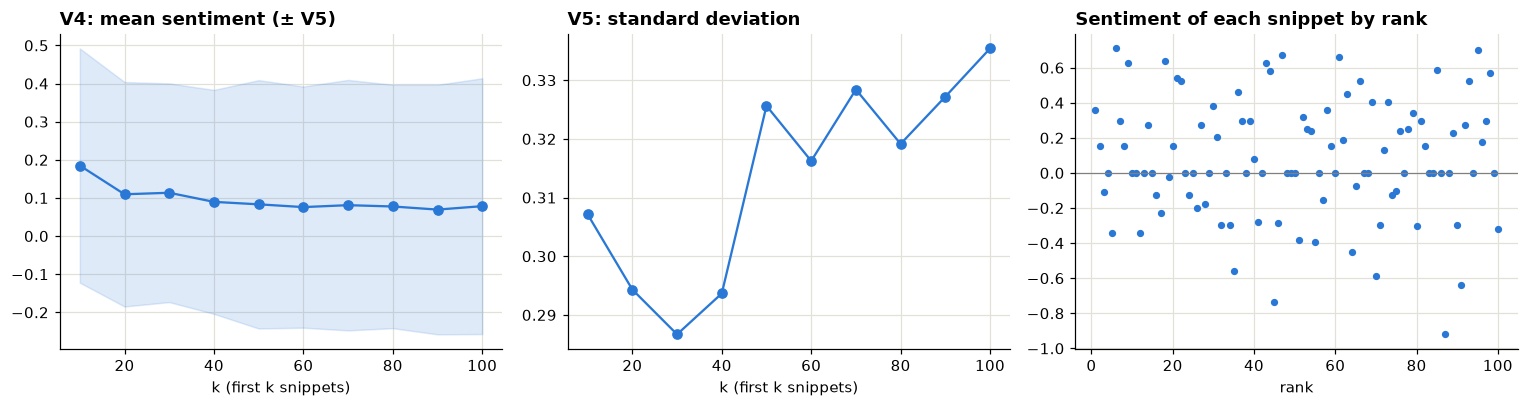

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].plot(sent.index, sent.V4, marker="o", color=BLUE)
axes[0].fill_between(
    sent.index, sent.V4 - sent.V5, sent.V4 + sent.V5, alpha=0.15, color=BLUE
)
axes[0].set_title("V4: mean sentiment (± V5)")
axes[1].plot(sent.index, sent.V5, marker="o", color=BLUE)
axes[1].set_title("V5: standard deviation")
axes[2].scatter(d["rank"], d.compound, s=14, color=BLUE)
axes[2].axhline(0, color="grey", lw=0.8)
axes[2].set_title("Sentiment of each snippet by rank")
for ax in axes[:2]:
    ax.set_xlabel("k (first k snippets)")
axes[2].set_xlabel("rank")
fig.tight_layout()